In [32]:
import numpy as np
import sklearn
import pandas as pd
from itertools import cycle
from collections import Counter
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import *
from sklearn.gaussian_process.kernels import RBF
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

# Preliminary Analysis of Data

Do not do cross validation

Each line in the dataset specifies the following:
1. It is a summary of the results obtained from a 3x3 grid from a particular region. Each cell in the grid indicates a pixel
2. The region has data in 4 channels (each pixel is described by 4 values).
3. Each value is obtained from an image, hence ranges from 0 to 255.
4. For this grid, there is a classification given : for the land cover ranging from 1 to 7 (exception - no class 6 in the dataset)

# Preparing the Dataset in proper format

Run only once

In [7]:
train_data_path = "data/sat.trn"
test_data_path  = "data/sat.tst"

In [8]:
with open(train_data_path, "r") as f:
    train_data = f.readlines()
train_data = np.array([line.split(' ') for line in train_data]).astype(np.int16)
train_dataset = pd.DataFrame(train_data) 

In [9]:
with open(test_data_path, "r") as f:
    test_data = f.readlines()
test_data = np.array([line.split(' ') for line in test_data]).astype(np.int16)
test_dataset = pd.DataFrame(test_data)

In [10]:
cols = [f'X{i}' for i in range(len(train_data[0, :-1]))] + ['Y']
train_dataset.columns = cols
test_dataset.columns = cols

In [11]:
test_dataset

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X27,X28,X29,X30,X31,X32,X33,X34,X35,Y
0,80,102,102,79,76,102,102,79,76,102,...,87,79,107,109,87,79,107,113,87,3
1,76,102,102,79,76,102,106,83,76,102,...,87,79,107,113,87,79,103,104,83,3
2,80,98,106,79,76,94,102,76,76,94,...,79,79,95,100,79,79,95,96,75,4
3,76,94,102,76,76,94,102,76,76,94,...,79,79,95,96,75,79,95,100,75,4
4,76,94,102,76,76,94,102,76,76,89,...,75,79,95,100,75,75,95,100,79,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,60,83,96,85,64,87,100,88,64,83,...,92,66,87,108,89,63,83,104,85,1
1996,64,79,100,85,56,71,96,85,56,68,...,85,66,83,100,85,63,83,100,81,1
1997,56,68,91,81,56,64,91,81,53,64,...,81,59,87,96,81,63,83,92,74,5
1998,56,68,87,74,60,71,91,81,60,64,...,74,59,83,92,74,59,83,92,70,5


In [12]:
train_dataset.to_csv('data/train.csv', index=False)
test_dataset.to_csv('data/test.csv', index=False)

# EDA

In [12]:
train_dataset = pd.read_csv('data/train.csv')
test_dataset  = pd.read_csv('data/test.csv')

In [13]:
train_dataset

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X27,X28,X29,X30,X31,X32,X33,X34,X35,Y
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,3
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,3
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,3
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,3
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430,56,64,108,96,64,71,108,96,68,75,...,92,66,83,108,96,66,87,104,89,5
4431,64,71,108,96,68,75,108,96,71,87,...,96,66,87,104,89,63,87,104,89,5
4432,68,75,108,96,71,87,108,88,71,91,...,89,63,87,104,89,70,100,104,85,4
4433,71,87,108,88,71,91,100,81,76,95,...,89,70,100,104,85,70,91,104,85,4


In [14]:
test_dataset

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X27,X28,X29,X30,X31,X32,X33,X34,X35,Y
0,80,102,102,79,76,102,102,79,76,102,...,87,79,107,109,87,79,107,113,87,3
1,76,102,102,79,76,102,106,83,76,102,...,87,79,107,113,87,79,103,104,83,3
2,80,98,106,79,76,94,102,76,76,94,...,79,79,95,100,79,79,95,96,75,4
3,76,94,102,76,76,94,102,76,76,94,...,79,79,95,96,75,79,95,100,75,4
4,76,94,102,76,76,94,102,76,76,89,...,75,79,95,100,75,75,95,100,79,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,60,83,96,85,64,87,100,88,64,83,...,92,66,87,108,89,63,83,104,85,1
1996,64,79,100,85,56,71,96,85,56,68,...,85,66,83,100,85,63,83,100,81,1
1997,56,68,91,81,56,64,91,81,53,64,...,81,59,87,96,81,63,83,92,74,5
1998,56,68,87,74,60,71,91,81,60,64,...,74,59,83,92,74,59,83,92,70,5


Standardize the features

In [15]:
X_train, y_train = train_dataset.drop(columns=['Y']), train_dataset['Y']
X_train_std = StandardScaler().fit_transform(X_train)

X_test, y_test = test_dataset.drop(columns=['Y']), test_dataset['Y']
X_test_std = StandardScaler().fit_transform(X_test)

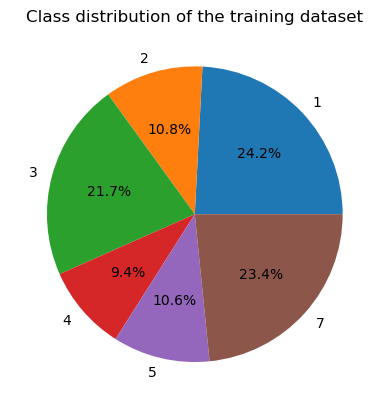

In [16]:
labels = list(set(train_dataset['Y']))
class_dist = {label : len(train_dataset[train_dataset['Y'] == label]) for label in labels}
plt.pie(x = class_dist.values(), labels=labels, autopct='%1.1f%%')
plt.title("Class distribution of the training dataset")
plt.savefig("images/class_dist_train.png")
plt.show()

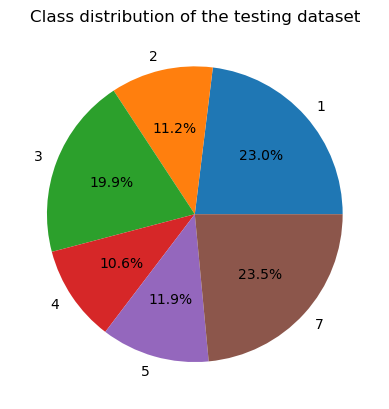

In [17]:
labels = list(set(test_dataset['Y']))
class_dist = {label : len(test_dataset[test_dataset['Y'] == label]) for label in labels}
plt.pie(x = class_dist.values(), labels=labels, autopct='%1.1f%%')
plt.title("Class distribution of the testing dataset")
plt.savefig("images/class_dist_test.png")
plt.show()

We see that both training and testing datasets have the same ratio of classes, and the class proportion of 1, 3, and 7 are same, and so is same for 2, 4 and 5. So, overall, balanced dataset

# Setup of the Machinery

In [109]:
classifiers = [
    KNeighborsClassifier(n_neighbors=7),  # Inherent Multiclass
    DecisionTreeClassifier(random_state=42),  # Inherent Multiclass
    DummyClassifier(),  # Inherent Multiclass
    LogisticRegression(),  # One vs the Rest
    GaussianNB(),  # Inherent Multiclass
    SVC(probability=True, random_state=42),  # One vs One
    RandomForestClassifier(random_state=42),  # Inherent Multiclass
    GradientBoostingClassifier(random_state=42),  # One vs the Rest
    AdaBoostClassifier(random_state=42),  # Inherent
    GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42, multi_class='one_vs_rest'),  # One vs the Rest
    MLPClassifier(random_state=42),  # Inherent Multiclass
    QuadraticDiscriminantAnalysis()  # Inherent Multiclass
]
names = [
    "KNNs",
    "Decision Tree",
    "Dummy",
    "Logisitic",
    "Naive Bayes",
    "SVC",
    "Random Forest",
    "GradBoost",
    "AdaBoost",
    "Gaussian Process",
    "MLP",
    "QDA"
]
cul_report = dict()
total_df = dict()

In [110]:
def report_generator(y_pred, y_test, name):
    n_classes = 7
    precision = dict()
    recall = dict()
    average_precision = dict()

    y_test_bin = label_binarize(y_test, classes=list(range(1, 7)))
    y_pred_bin = label_binarize(y_pred, classes=list(range(1, 7)))
    for i in range(n_classes):
        if i != 6:
            precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_pred_bin[:, i])
            average_precision[i] = average_precision_score(y_test_bin[:, i], y_pred_bin[:, i])
    precision["micro"], recall["micro"], _ = precision_recall_curve(y_test_bin.ravel(), y_pred_bin.ravel())
    average_precision["micro"] = average_precision_score(y_test_bin, y_pred_bin, average="micro")
    
    report = {
        "name": name,
        "precision": precision,
        "recall": recall,
        "avg_p": average_precision,
        # "pr_curve": precision_recall_curve(y_test, y_pred),
        "f1": f1_score(y_test, y_pred, average='micro'),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        # "roc_curve": roc_curve(y_test, y_pred),
        # "likelihood_ratios": class_likelihood_ratios(y_test, y_pred),
        "bal_acc": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test_bin, y_pred_bin, average='micro', multi_class='ovr')
    }

    return report

In [111]:
def classify(model, train_x, train_y, test_x, test_y, name):
    model = model.fit(train_x, train_y)
    pred = model.predict(test_x)

    r = report_generator(pred, test_y, name)
    k = ['name', 'precision','recall','f1','bal_acc','mcc','accuracy','roc_auc','avg_p']
    new_r1 = {i: r[i] for i in k}
    # df = pd.DataFrame.from_dict(new_r1, orient='index', columns=['Score']).transpose()

    cul_report[name] = new_r1
    # total_df[name] = df

In [112]:
def comparison_metrics():
    # Plot of Report generated using sklearn
    metrics = list(cul_report[list(cul_report.keys())[0]].keys())

    fig, axs = plt.subplots(4, 2, figsize = (25, 15))
    i, j = 0, 0
    color_palette = [
        '#1A1A1A',  # Onyx
        '#D55E00',  # Vermillion
        '#0072B2',  # Cerulean Blue
        '#009E73',  # Shamrock Green
        '#56B4E9',  # Sky Blue
        '#E69F00',  # Amber
        '#CC79A7',  # Pale Violet
        '#F0E442',  # Canary Yellow
        '#999999'   # Gray
    ]
    for metric in metrics:
        print(metric)
        ax = axs[i, j]
        vals = [cul_report[report][metric] for report in cul_report]
        ax.bar(x=list(cul_report.keys()), height=vals, color=color_palette)
        ax.tick_params(axis='x', labelrotation=45)
        ax.set_ylabel(f"{metric.capitalize()} Value")
        # if not all(isinstance(i, tuple) for i in vals):
        #     m = 1.1 if max(vals) > 0.7 else max(vals) + 0.05
        #     n = 0 if min(vals) < 0.3 else min(vals) - 0.05
        #     ax.set_ylim(n, m)
        ax.set_title(f"{metric} value across different methods")
        # for q in range(len(vals)):
        #     ax.text(q, vals[q], np.round(vals[q], 2), ha='center')  # Aligning text at center
        j += 1
        if j == 2:
            i += 1
            j = 0

    fig.suptitle("Comparison of different methods", fontsize='xx-large')
    plt.savefig("images/total_cul_report.png")
    plt.subplots_adjust(wspace=0.1, hspace=1.5)
    plt.show()

In [113]:
# def roc_curve(train_x, train_y, test_x, test_y):
#     # ROC
#     roc_curves = {report:(cul_report[report]['roc_curve'], cul_report[report]['roc_auc']) for report in cul_report}
#     plt.figure(figsize=(8, 6))
#     color_palette = [
#         '#D55E00',  # Vermillion
#         '#0072B2',  # Cerulean Blue
#         '#009E73',  # Shamrock Green
#         '#56B4E9',  # Sky Blue
#         '#E69F00',  # Amber
#         '#CC79A7',  # Pale Violet
#         '#F0E442',  # Canary Yellow
#         '#999999',   # Gray
#         '#882255',
#         '#1A1A1A',  # Onyx
#     ]
#     k = list(roc_curves.keys())
#     for i in range(len(k)):
#         roc, roc_auc = roc_curves[k[i]]
#         fpr, tpr, thresholds = roc
#         plt.plot(fpr, tpr, color=color_palette[i], lw=2, label=f"{k[i]} with auc={roc_auc:.2f}") # Plot Model 1's ROC curve

#     # Plot the random chance line (diagonal line)
#     plt.plot([0, 1], [0, 1], color=color_palette[-1], lw=2, linestyle='--', label='Random Chance')

#     plt.xlabel('False Positive Rate (FPR)')
#     plt.ylabel('True Positive Rate (TPR)')
#     plt.title('Receiver Operating Characteristic (ROC) Curves for Multiple Models')
#     plt.legend(loc='lower right')
#     plt.grid(True)
#     plt.savefig("images/roc_curves.png")
#     plt.show()


In [114]:
def pr_curves(train_x, train_y, test_x, test_y):
    # PR Curve
    pr_curves = {
        report: (
            cul_report[report]['precision']['micro'],
            cul_report[report]['recall']['micro'],
            cul_report[report]['avg_p']['micro']
            ) for report in cul_report
    }
    plt.figure(figsize=(8, 6))
    color_palette = [
        '#D55E00',  # Vermillion
        '#0072B2',  # Cerulean Blue
        '#009E73',  # Shamrock Green
        '#56B4E9',  # Sky Blue
        '#E69F00',  # Amber
        '#CC79A7',  # Pale Violet
        '#F0E442',  # Canaryp,  Yellow
        '#999999',   # Gray
        '#882255',
        '#1A1A1A',  # Onyx
    ]
    k = list(pr_curves.keys())
    for i in range(len(k)):
        pr, recall, avg_p = pr_curves[k[i]]
        display = PrecisionRecallDisplay(
            recall=recall,
            precision=pr,
            average_precision=avg_p,
            prevalence_pos_label=Counter(test_y.ravel())[1] / test_y.size,
        )
        display.plot(plot_chance_level=True, despine=True)
        _ = display.ax_.set_title("Micro-averaged over all classes")
        plt.savefig("images/pr_curves.png")
        plt.grid(True)
        plt.show()

        # setup plot details
        colors = cycle(["navy", "turquoise", "darkorange", "cornflowerblue", "teal"])

        _, ax = plt.subplots(figsize=(7, 8))

        f_scores = np.linspace(0.2, 0.8, num=4)
        lines, labels = [], []
        for f_score in f_scores:
            x = np.linspace(0.01, 1)
            y = f_score * x / (2 * x - f_score)
            (l,) = plt.plot(x[y >= 0], y[y >= 0], color="gray", alpha=0.2)
            plt.annotate("f1={0:0.1f}".format(f_score), xy=(0.9, y[45] + 0.02))

        display = PrecisionRecallDisplay(
            recall=recall["micro"],
            precision=precision["micro"],
            average_precision=average_precision["micro"],
        )
        display.plot(ax=ax, name="Micro-average precision-recall", color="gold")

        for i, color in zip(range(n_classes), colors):
            display = PrecisionRecallDisplay(
                recall=recall[i],
                precision=precision[i],
                average_precision=average_precision[i],
            )
            display.plot(
                ax=ax, name=f"Precision-recall for class {i}", color=color, despine=True
            )

        # add the legend for the iso-f1 curves
        handles, labels = display.ax_.get_legend_handles_labels()
        handles.extend([l])
        labels.extend(["iso-f1 curves"])
        # set the legend and the axes
        ax.legend(handles=handles, labels=labels, loc="best")
        ax.set_title("Extension of Precision-Recall curve to multi-class")

        plt.show()
    # Plot the random chance line (diagonal line)
    # plt.plot([0, 1], [0.5, 0.5], color=color_palette[-1], lw=2, linestyle='--', label='Baseline')
    # plt.xlabel('Recall')
    # plt.ylabel('Precision')
    # plt.title('Precision-Recall Curves for Multiple Models')
    # plt.legend(loc='lower left', fontsize=8)
    # plt.grid(True)
    # plt.savefig("images/pr_curves.png")
    # plt.show()

# Performing Experiments

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/tmp/ipykernel_6929/2030253413.py:30: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  prevalence_pos_label=Counter(test_y.ravel())[1] / test_y.size,


<Figure size 800x600 with 0 Axes>

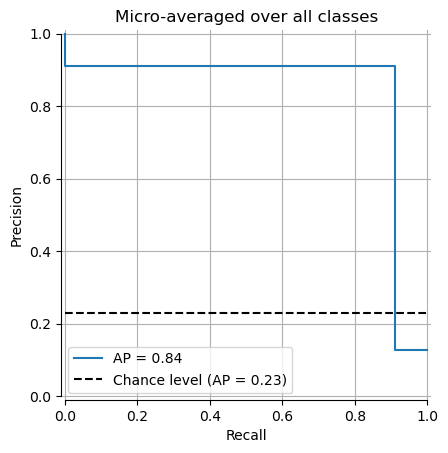

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

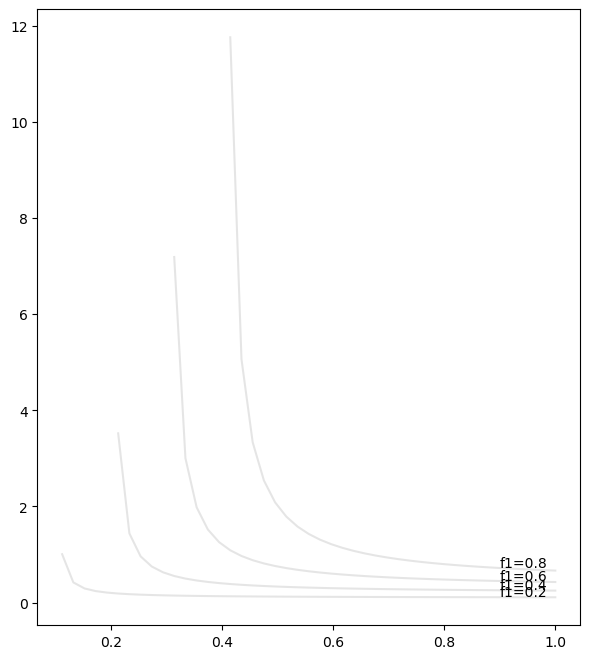

In [115]:
for name, classifier in zip(names, classifiers):
    classify(classifier, X_train_std, y_train, X_test_std, y_test, name)
    # comparison_metrics()
    pr_curves(X_train_std, y_train, X_test_std, y_test)

In [ ]:
comp_df = pd.concat(total_df, axis=0)

# Results

# Conclusion